# Plots

The three charts of the project, drawn from the tables of `boxbox.analysis`. Every plot function returns a figure, so here we show it and save it as a PNG for the README.

Race: Bahrain 2022 (dry).

In [1]:
import os
import sys

# The notebooks live in notebooks/, the package in the project root.
sys.path.append(os.path.abspath(os.path.join("..")))

# Reload boxbox automatically when a .py file changes.
%load_ext autoreload
%autoreload 2

## Imports and folder for the images

In [2]:
from boxbox.analysis import (
    driver_strategies,
    get_stints,
    race_pace,
    tyre_degradation,
)
from boxbox.cleaning import mark_clean_laps
from boxbox.data import get_laps, prepare_laps
from boxbox.plots import plot_degradation, plot_race_pace, plot_strategies

IMAGES_DIR = "../images"
os.makedirs(IMAGES_DIR, exist_ok=True)

## Data

The clean laps are only used for the pace; the strategy uses all the laps.

In [3]:
laps = mark_clean_laps(prepare_laps(get_laps(2022, "bahrain")))
clean = laps[laps["is_clean"]]
print(len(clean), "clean laps of", len(laps))

854 clean laps of 1125


## Question 1: who is fastest?

One bar per driver: the gap in seconds to the fastest median clean lap. The
colour is the team, so teammates can be compared at a glance. LEC, the
reference, has no bar.

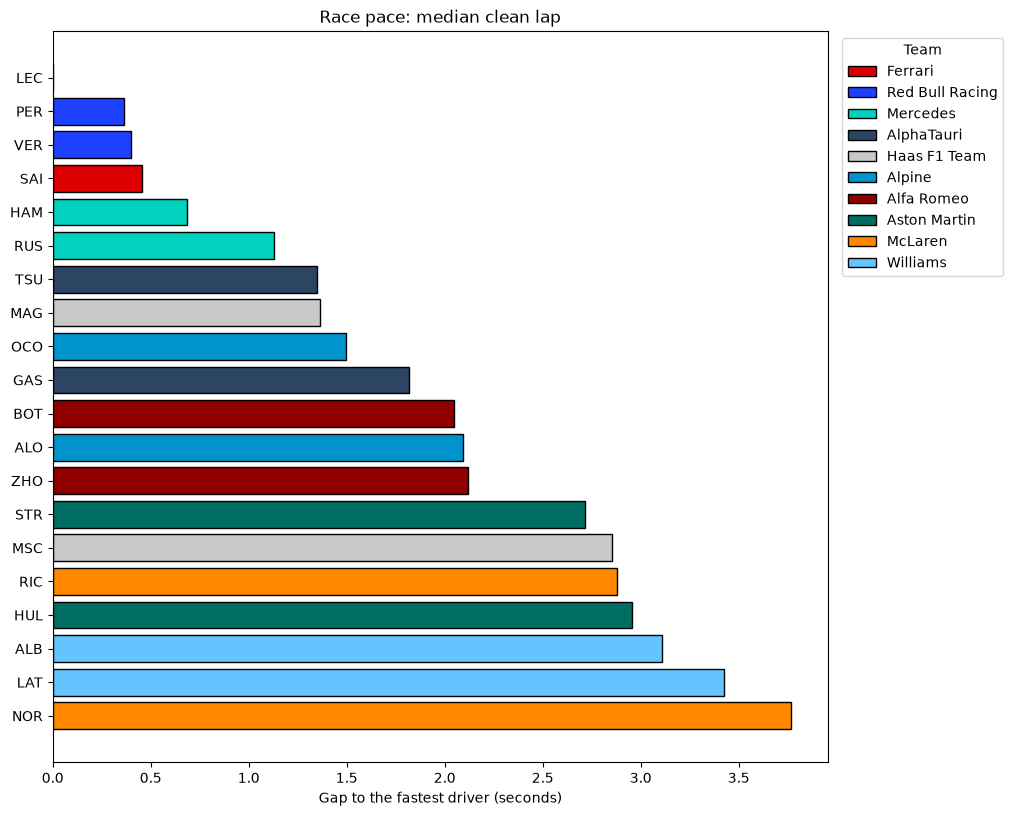

In [4]:
pace = race_pace(laps)
fig = plot_race_pace(pace)
fig.savefig(os.path.join(IMAGES_DIR, "race_pace.png"), dpi=150, bbox_inches="tight")

## Question 2: which tyre strategies?

One row per driver, in finishing order. Each block is a stint, coloured by
compound. A row that stops early is a driver who retired (VER, GAS).

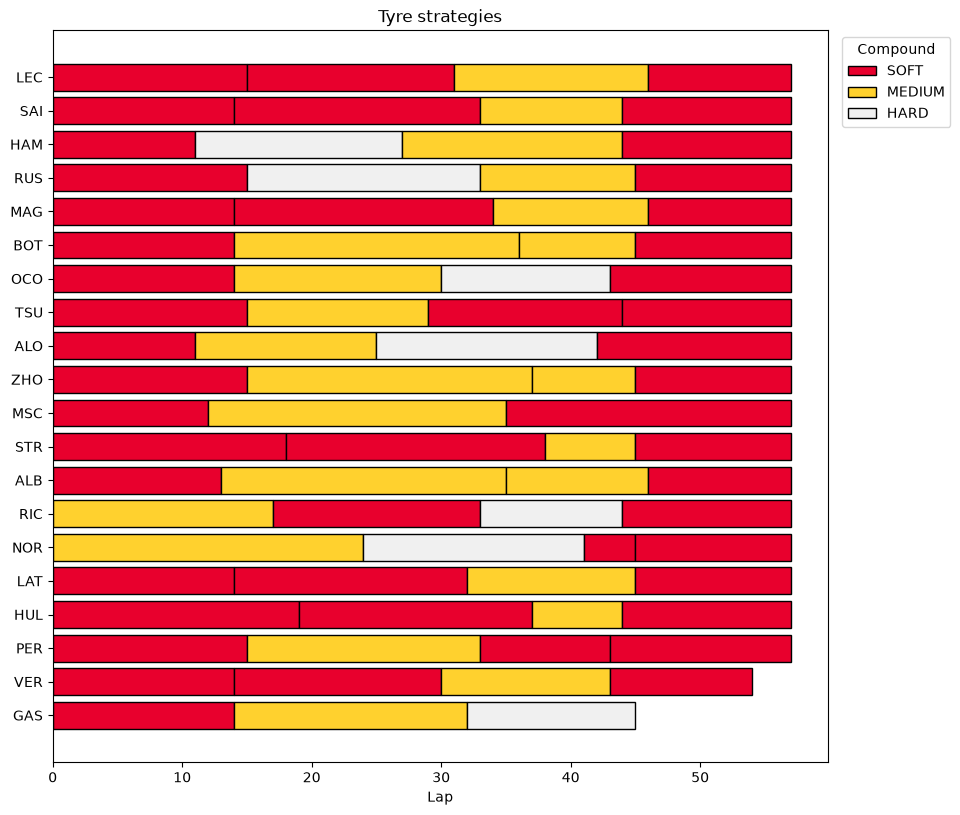

In [5]:
stints = get_stints(laps)
strategies = driver_strategies(laps)
fig = plot_strategies(stints, drivers=strategies["drv"].tolist())
fig.savefig(os.path.join(IMAGES_DIR, "strategies.png"), dpi=150, bbox_inches="tight")

## Question 3: how fast do the tyres wear?

One dot per stint (stints with at least 10 clean laps), grouped by compound.
The height is the lap time lost per lap of tyre age, the black line is the
median of the compound, and the number under each name is the number of
stints. A dot below the grey zero line is a stint whose lap times fell.

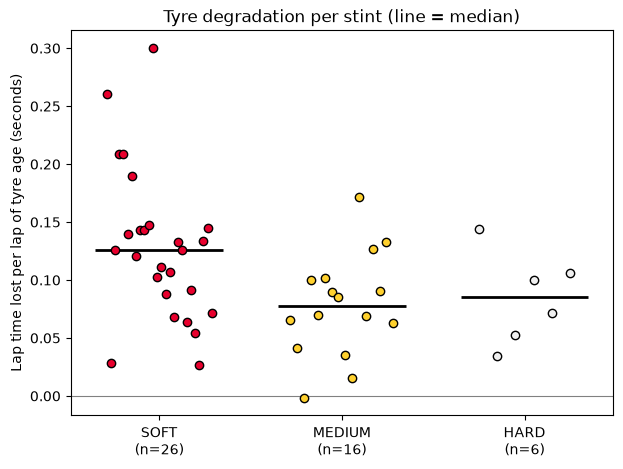

In [6]:
degradation = tyre_degradation(laps)
fig = plot_degradation(degradation)
fig.savefig(os.path.join(IMAGES_DIR, "degradation.png"), dpi=150, bbox_inches="tight")

In [7]:
# The numbers behind the chart.
degradation.groupby("compound")["degradation_per_lap"].agg(
    ["count", "median", "min", "max"]
)

,count,median,min,max
compound,,,,
HARD,6,0.085778,0.034167,0.144091
MEDIUM,16,0.077436,-0.001765,0.171615
SOFT,26,0.125824,0.026933,0.300190


**Reading:** SOFT wears fastest (median about 0.126 s per lap). MEDIUM
(about 0.077) and HARD (about 0.086) are too close to rank, and HARD has only
6 stints. The dots overlap a lot: stints vary more than the compounds differ.